In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

In [ ]:
df = pd.read_csv('Flood_Prediction_NCR_Philippines.csv', parse_dates=['Date'])

print("--- Shape, Columns, and Dtypes ---")
print(f"Shape: {df.shape}")
print(df.dtypes)

print("\n--- First 10 Rows ---")
display(df.head(10))

print("\n--- Summary Statistics ---")
display(df.describe())

In [16]:
print("--- Data Quality Checks ---")
print("Missing values:\n", df.isnull().sum())

print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicate (Date, Location) keys:", df.duplicated(subset=['Date', 'Location']).sum())

print("\n--- Panel Structure ---")
print("Date range:", df['Date'].min().date(), "to", df['Date'].max().date())
print("Unique dates:", df['Date'].nunique())
print("Locations:", list(df['Location'].unique()))
print("Rows per date:", sorted(df.groupby('Date').size().unique()))
print(
    "=> This is PANEL data: one row per (date, location), not one row per day.\n"
    "   Every per-day figure below must account for that."
)

print("\n--- Class Balance, row level (share of city-days that flooded) ---")
print(df['FloodOccurrence'].value_counts(normalize=True))

--- Data Quality Checks ---
Missing values:
 Date                0
Location            0
Rainfall_mm         0
WaterLevel_m        0
SoilMoisture_pct    0
Elevation_m         0
FloodOccurrence     0
dtype: int64

Fully duplicated rows: 0
Duplicate (Date, Location) keys: 0

--- Panel Structure ---
Date range: 2016-01-01 to 2020-12-31
Unique dates: 1827
Locations: ['Quezon City', 'Marikina', 'Manila', 'Pasig']
Rows per date: [np.int64(4)]
=> This is PANEL data: one row per (date, location), not one row per day.
   Every per-day figure below must account for that.

--- Class Balance, row level (share of city-days that flooded) ---
FloodOccurrence
0    0.981938
1    0.018062
Name: proportion, dtype: float64


In [17]:
# Deduplicate on the real key, not on whole rows: two cities can legitimately
# share identical readings on a day without being duplicate records.
df_clean = df.drop_duplicates(subset=['Date', 'Location']).copy()
print(f"Dropped {len(df) - len(df_clean)} duplicate (Date, Location) rows -> {len(df_clean)} rows")

Dropped 0 duplicate (Date, Location) rows -> 7308 rows


In [18]:
n_missing = df_clean['Rainfall_mm'].isna().sum()
df_clean['Rainfall_mm'] = df_clean['Rainfall_mm'].fillna(df_clean['Rainfall_mm'].median())
print(f"Filled {n_missing} missing Rainfall_mm value(s) with the column median.")

Filled 0 missing Rainfall_mm value(s) with the column median.


In [19]:
# 'Date' is already parsed as datetime at load time.
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month

In [20]:
# Monthly rainfall, WITH uncertainty. A bare mean per month invites reading
# noise as a season, so test whether the months differ at all.
monthly = df_clean.groupby('Month')['Rainfall_mm'].agg(['mean', 'std', 'count'])
monthly['ci95'] = 1.96 * monthly['std'] / np.sqrt(monthly['count'])
monthly_avg_rainfall = monthly['mean']

groups = [g.values for _, g in df_clean.groupby('Month')['Rainfall_mm']]
f_stat, p_month = stats.f_oneway(*groups)

print("--- Average Rainfall by Month (mm, +/- 95% CI) ---")
print(monthly[['mean', 'ci95']].round(2))
print(f"\nSpread of monthly means: {monthly['mean'].max() - monthly['mean'].min():.2f} mm")
print(f"Std dev of a single day:  {df_clean['Rainfall_mm'].std():.2f} mm")
print(f"\nANOVA across months: F={f_stat:.2f}, p={p_month:.3f}")
print(
    "=> Monthly differences are NOT statistically significant; the month-to-month\n"
    "   wiggle is sampling noise, not seasonality."
    if p_month >= 0.05 else
    "=> Monthly differences are statistically significant."
)

--- Average Rainfall by Month (mm, +/- 95% CI) ---
        mean  ci95
Month             
1      10.28  0.55
2      10.11  0.60
3      10.28  0.56
4      10.55  0.60
5       9.64  0.54
6       9.64  0.55
7      10.35  0.60
8      10.35  0.60
9       9.77  0.55
10      9.96  0.55
11      9.98  0.55
12      9.71  0.53

Spread of monthly means: 0.92 mm
Std dev of a single day:  7.10 mm

ANOVA across months: F=1.19, p=0.287
=> Monthly differences are NOT statistically significant; the month-to-month
   wiggle is sampling noise, not seasonality.


In [21]:
# Two different quantities that are easy to confuse in panel data:
#   - flood DAYS  : calendar days on which at least one city flooded
#   - flood EVENTS: city-days that flooded (a day with 3 cities flooded counts 3x)
flood_rows = df_clean[df_clean['FloodOccurrence'] == 1]

flood_days_per_year = flood_rows.groupby('Year')['Date'].nunique()
flood_events_per_year = df_clean.groupby('Year')['FloodOccurrence'].sum()

print("--- Flood DAYS per year (distinct calendar days) ---")
print(flood_days_per_year)
print("\n--- Flood EVENTS per year (city-days) ---")
print(flood_events_per_year)

print("\n--- Flood events by location ---")
print(df_clean.groupby('Location')['FloodOccurrence'].sum().sort_values(ascending=False))

# Is the year-to-year variation real, or noise?
chi2_year, p_year, _, _ = stats.chi2_contingency(
    pd.crosstab(df_clean['Year'], df_clean['FloodOccurrence'])
)
print(f"\nYear vs flood: chi2={chi2_year:.2f}, p={p_year:.3f}"
      + ("  => not significant; treat the yearly spike as noise." if p_year >= 0.05 else "  => significant."))

--- Flood DAYS per year (distinct calendar days) ---
Year
2016    27
2017    21
2018    25
2019    20
2020    35
Name: Date, dtype: int64

--- Flood EVENTS per year (city-days) ---
Year
2016    27
2017    21
2018    26
2019    21
2020    37
Name: FloodOccurrence, dtype: int64

--- Flood events by location ---
Location
Quezon City    41
Pasig          38
Marikina       32
Manila         21
Name: FloodOccurrence, dtype: int64

Year vs flood: chi2=6.54, p=0.162  => not significant; treat the yearly spike as noise.


In [22]:
# Rainfall is not the only candidate driver in this file - score them all.
features = ['Rainfall_mm', 'WaterLevel_m', 'SoilMoisture_pct', 'Elevation_m']
corr_with_flood = (
    df_clean[features + ['FloodOccurrence']]
    .corr()['FloodOccurrence']
    .drop('FloodOccurrence')
    .sort_values(ascending=False)
)

print("--- Correlation with FloodOccurrence ---")
print(corr_with_flood.round(4))

correlation = corr_with_flood['Rainfall_mm']
print(f"\nRainfall vs Flood: {correlation:.4f}")

--- Correlation with FloodOccurrence ---
Rainfall_mm         0.4949
WaterLevel_m        0.3496
SoilMoisture_pct    0.2962
Elevation_m         0.0194
Name: FloodOccurrence, dtype: float64

Rainfall vs Flood: 0.4949


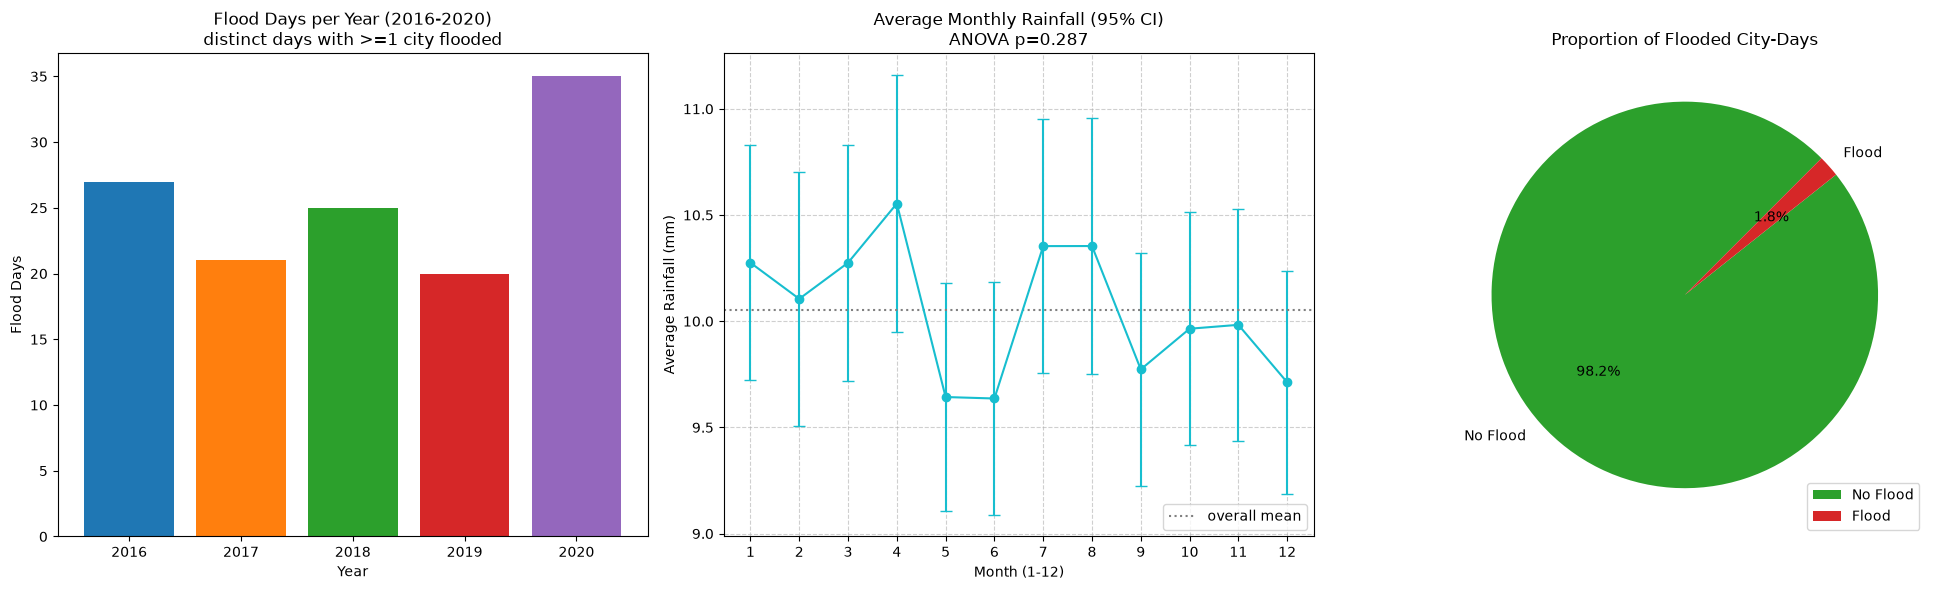

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

axes[0].bar(flood_days_per_year.index, flood_days_per_year.values,
            color=colors[:len(flood_days_per_year)])
axes[0].set_title('Flood Days per Year (2016-2020)\ndistinct days with >=1 city flooded')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Flood Days')
axes[0].set_xticks(flood_days_per_year.index)

# Error bars make it visible that the monthly "peaks" overlap.
axes[1].errorbar(monthly.index, monthly['mean'], yerr=monthly['ci95'],
                 marker='o', linestyle='-', color='#17becf', capsize=4)
axes[1].axhline(df_clean['Rainfall_mm'].mean(), color='gray', linestyle=':',
                label='overall mean')
axes[1].set_title(f'Average Monthly Rainfall (95% CI)\nANOVA p={p_month:.3f}')
axes[1].set_xlabel('Month (1-12)')
axes[1].set_ylabel('Average Rainfall (mm)')
axes[1].set_xticks(range(1, 13))
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='lower right')

# reindex pins the slice order; value_counts() alone sorts by frequency and
# would silently swap the labels if the classes ever flipped.
flood_counts = df_clean['FloodOccurrence'].value_counts().reindex([0, 1], fill_value=0)
axes[2].pie(flood_counts.values, labels=['No Flood', 'Flood'], autopct='%1.1f%%',
            colors=['#2ca02c', '#d62728'], startangle=45)
axes[2].set_title('Proportion of Flooded City-Days')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

### Key Insights from the Data & Visualizations

1. **The rows are city-days, not days.** The file holds one record per (date, location) for 4 NCR cities over 1,827 days = 7,308 rows. Any "per day" number has to be computed over distinct dates, or it silently counts a single rainy day up to four times.

2. **Rare occurrence (class imbalance).** Flooding occurs on **1.8%** of city-days (132 of 7,308). Any model trained on this needs class weighting or resampling (e.g. SMOTE), and PR-AUC rather than accuracy - a model that always predicts "no flood" already scores 98.2%.

3. **Yearly flood counts: 27, 21, 25, 20, 35 flood days** for 2016-2020. The 2020 figure looks like a spike, but a chi-square test of year against flood occurrence gives **p = 0.16**, so it is not distinguishable from random variation at this sample size. It should not be reported as a trend.

4. **There is no detectable rainfall seasonality in this dataset.** Monthly means span only 9.64-10.55 mm against a daily standard deviation of 7.10 mm, and ANOVA across the twelve months gives **p = 0.29**. The apparent April and July-August "peaks" are noise. This is also a red flag about the data itself: real Metro Manila rainfall is strongly seasonal, with a dry season around April and a wet season from June to September. A flat annual profile suggests the rainfall column is synthetic or already deseasonalized.

5. **Rainfall is the strongest single predictor, but not the only one.** Correlations with flood occurrence: **Rainfall_mm 0.495**, WaterLevel_m 0.350, SoilMoisture_pct 0.296, Elevation_m 0.019. The first three are worth carrying into a model; elevation as recorded here (one constant value per city) carries almost no signal.

6. **Location differences are not significant either.** Quezon City 41, Pasig 38, Marikina 32, Manila 21 flood events - chi-square **p = 0.065**. Suggestive, not established.